# 9-10. auto_arima vs GARCH vs SV 종합 비교

**전체 계획**: `9-1`~`9-4` auto_arima 기반 검증, `9-5` GARCH·SV 구현, `9-6`·`9-7` GARCH(원/로그), `9-8`·`9-9` SV(원/로그), **`9-10` 종합 비교(이 노트북)**.

**비교 구성**: 스케일(원 / 로그) 안에서 모델끼리 비교한다. 스케일마다 점예측 정의와 구간 모양이 달라 모델 차이만 보려면 같은 스케일끼리 비교해야 한다.

| 모델 | 설명 |
|---|---|
| auto_arima | `9-3`·`9-4` 결과(d=1, AICc, **q 허용**) |
| AR단독 | `9-5`의 기준선(d=1, AR만 허용, AICc, p≤3, 절편 없음). 이 노트북에서 계산 |
| GARCH | `9-6`·`9-7`(AR(p)+GARCH(1,1) 동시최적화) |
| SV | `9-8`·`9-9`(AR(p)+SV(1) 동시최적화) |

**리샘플링 구간**은 모델 구조에 맞춰 만든다. auto_arima·AR단독은 분산이 일정하므로 과거 원 오차를 중앙값으로 중심화해 쓰고, GARCH·SV는 시점마다 σ_h가 달라 과거 오차를 σ_h로 표준화한 뒤 중심화하고 현재 σ_h를 곱해 쓴다(필터링된 과거 시뮬레이션, `9-6`~`9-9`의 설명 참고). 두 구간 방식의 점예측은 같다.

GARCH/SV는 AR만 쓰므로 평균식이 같은 **AR단독이 공정한 기준선**이다. auto_arima는 q를 허용해 평균식이 달라 참고로 둔다. 모델마다 **자체 구간**과 **리샘플링 구간**이 있어 스케일당 8개 조합을 비교한다.

**평가**: CRPS(7분위), 90% 커버리지, 구간폭, MSE, 그리고 같은 폭 비교(90% 도달 배율 k에서의 구간점수, k는 진단용). 22개 origin이 겹치므로 서술 비교이고 유의성 검정은 하지 않는다.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE, P_MAX, SCALE = 1, 500, 3, 100.0

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
LOG = SCALE * np.log(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
FIRST = scored_origins[0]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


def to_orig(x):
    return np.exp(np.asarray(x) / SCALE)


def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def level_sigma(ar_coefs, d, innov_var):
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def select_p(train):
    # AR단독 auto_arima(정확우도, AICc): d=1 고정, MA 없음, 절편 없음 -> GARCH의 AR 차수로 사용
    m = pm.auto_arima(train, d=D, seasonal=False, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc",
                      with_intercept=False, suppress_warnings=True, error_action="ignore")
    return m.order[0], m


def ar_fallback(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


def garch_forecast(train, p):
    diff_train, hist = difference(train, D)
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, D)
    sig = level_sigma(ar, D, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def model_forecast(series):
    # AR 차수 p는 AR단독 auto_arima가 선택, 적합 실패 시 AR단독 예측으로 대체(대체 횟수는 기록)
    p, m = select_p(series)
    try:
        fc, sig = garch_forecast(series, p)
        return fc, sig, "GARCH", p
    except Exception:
        fc, sig = ar_fallback(m)
        return fc, sig, "AR대체", p


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2 ** 32))

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
ALPHA_IS = ALPHA
print(f"채점 origin {len(scored_origins)}개, h=1~{H}")


채점 origin 22개, h=1~4


## 1. AR단독 기준선 계산

`9-6`·`9-7`과 같은 절차(자체: pmdarima σ 기반 정규 구간, 리샘플링: 과거 h단계 오차 500개)로 AR단독 구간을 만든다. p는 origin마다 `auto_arima`(AICc, AR만)가 고른다.


In [2]:
def run_ar(logmode, seed_name):
    CACHE = f"../cache/cache_910_ar_{'log' if logmode else 'orig'}_df.pkl"
    if os.path.exists(CACHE):
        return pd.read_pickle(CACHE)
    rng = rng_for(seed_name)
    pool = {h: np.array([]) for h in range(1, H + 1)}
    rows = []
    tf = to_orig if logmode else (lambda x: x)
    for oi, o in enumerate(origins):
        train, actual = (LOG[:o] if logmode else vals[:o]), vals[o:o + H]
        p, m = select_p(train)
        fc, sig = ar_fallback(m)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                s_h = max(sig[h - 1], 1e-6)
                samples = fc[h - 1] + rng.choice(pool[h] - np.median(pool[h]), size=N_RESAMPLE, replace=True)
                q7_res = tf(np.quantile(samples, LEVELS))
                lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
                q7_self = tf(fc[h - 1] + s_h * stats.norm.ppf(LEVELS))
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h), tf(fc[h - 1] + Z * s_h)
                f_self = float(tf(fc[h - 1]))
                f_res = f_self
                rows.append({"origin": o, "h": h, "방식": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "MSE": ((a - f_res) / var_std) ** 2,
                             "CRPS(7분위)": crps7(q7_res, a), "구간폭": (hi_r - lo_r) / var_std, "lo": lo_r, "hi": hi_r, "fc": f_self, "actual": a})
                rows.append({"origin": o, "h": h, "방식": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "MSE": ((a - f_self) / var_std) ** 2,
                             "CRPS(7분위)": crps7(q7_self, a), "구간폭": (hi_n - lo_n) / var_std, "lo": lo_n, "hi": hi_n, "fc": f_self, "actual": a})
        for h in range(1, H + 1):
            pool[h] = np.append(pool[h], (np.log(actual[h - 1]) * SCALE if logmode else actual[h - 1]) - fc[h - 1])
    df = pd.DataFrame(rows)
    df.to_pickle(CACHE)
    return df


ar_orig = run_ar(False, "X3_l1_9-10_ar_orig")
ar_log = run_ar(True, "X3_l1_9-10_ar_log")
print(f"AR단독: 원 {len(ar_orig)}행, 로그 {len(ar_log)}행")


AR단독: 원 176행, 로그 176행


## 2. 결과 불러오기와 비교 함수

기존 결과(`9-3`, `9-4`, `9-6`~`9-9`)는 캐시에서 읽는다. `interval_at`은 구간을 점예측 기준으로 k배 늘리거나 줄여 같은 폭에서 비교하기 위한 함수다(로그는 로그 스케일에서 배율을 적용). 구간점수는 폭 + (2/α)x(벗어난 거리), α=0.10, `var_std`로 정규화한다.


In [3]:
SRC = {
    "orig": {"auto_arima": "cache_93_resample_vs_self_df", "AR단독": ar_orig, "GARCH": "cache_96_garch_orig_df", "SV": "cache_98_sv_orig_df"},
    "log": {"auto_arima": "cache_94_log_resample_vs_self_df", "AR단독": ar_log, "GARCH": "cache_97_garch_log_df", "SV": "cache_99_sv_log_df"},
}
KEEP = ["origin", "h", "방식", "적중", "MSE", "CRPS(7분위)", "구간폭", "lo", "hi", "fc", "actual"]
MODELS = ["auto_arima", "AR단독", "GARCH", "SV"]


def load(scale):
    parts = []
    for m in MODELS:
        s = SRC[scale][m]
        d = s if isinstance(s, pd.DataFrame) else pd.read_pickle(f"../cache/{s}.pkl")
        parts.append(d[KEEP].assign(모델=m))
    return pd.concat(parts, ignore_index=True)


def interval_at(g, k, logmode):
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if logmode:
        lo_k = np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc)))
        hi_k = np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    else:
        lo_k, hi_k = fc + k * (lo - fc), fc + k * (hi - fc)
    cov = np.mean((a >= lo_k) & (a <= hi_k)) * 100
    width = np.mean(hi_k - lo_k) / var_std
    iscore = np.mean((hi_k - lo_k) + (2 / ALPHA_IS) * np.maximum(lo_k - a, 0) + (2 / ALPHA_IS) * np.maximum(a - hi_k, 0)) / var_std
    return cov, width, iscore


def summarize(df, logmode):
    rows = []
    ks = np.linspace(0.2, 10, 981)
    for (m, name), g in df.groupby(["모델", "방식"]):
        k90 = next((k for k in ks if interval_at(g, k, logmode)[0] >= 90), np.nan)
        _, w90, is90 = interval_at(g, k90, logmode) if not np.isnan(k90) else (np.nan,) * 3
        rows.append({"모델": m, "구간": name, "커버리지(%)": g["적중"].mean(), "CRPS(7분위)": g["CRPS(7분위)"].mean(), "구간폭": g["구간폭"].mean(),
                     "MSE": g["MSE"].mean(), "90% 도달 k": k90, "90% 폭": w90, "90% 구간점수": is90})
    t = pd.DataFrame(rows).set_index(["모델", "구간"])
    return t.loc[[(m, n) for m in MODELS for n in ["자체", "리샘플링"]]]


def show(t, title):
    print(title)
    display(t.round(3).style.format("{:.3f}").highlight_min(subset=["CRPS(7분위)", "MSE", "90% 구간점수"], color="#FFF1D6")
            .highlight_min(subset=["구간폭"], color="#E6F1FA"))


def plot(t, title):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    x = np.arange(len(MODELS))
    for ax, (c, ttl) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"),
                                   ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)"), ("90% 구간점수", "(보조) 같은 90%로 맞춘 구간점수")]):
        for j, (name, col) in enumerate([("자체", "#0072B2"), ("리샘플링", "#E69F00")]):
            v = np.array([t.loc[(m, name), c] for m in MODELS])
            bars = ax.bar(x + (j - 0.5) * 0.38, v, 0.38, color=col, label=name)
            for b in bars:
                ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=7)
        allv = t[c].values
        best = (np.abs(allv - 90) if c.startswith("커버리지") else allv).argmin()
        m_b, n_b = t.index[best]
        j = 0 if n_b == "자체" else 1
        ax.patches[j * len(MODELS) + MODELS.index(m_b)].set_hatch("///")
        if c.startswith("커버리지"):
            ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
        ax.set_xticks(x)
        ax.set_xticklabels(MODELS, fontsize=8)
        ax.set_title(ttl, fontsize=10, fontweight="bold", color="#172033")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(title + " (빗금 = 8개 조합 중 최선)", fontsize=11)
    fig.tight_layout()
    plt.show()


def hwise(df):
    t = df.groupby(["모델", "방식", "h"])["CRPS(7분위)"].mean().unstack("h")
    return t.loc[[(m, n) for m in MODELS for n in ["자체", "리샘플링"]]]


def origin_rank(df):
    per = df.groupby(["모델", "방식", "origin"])["CRPS(7분위)"].mean().unstack(["모델", "방식"])
    return per.idxmin(axis=1).value_counts().to_frame("origin 수")


## 3. 원 스케일 비교 (8개 조합)


원 스케일 -- 22개 origin x h=1~4 평균


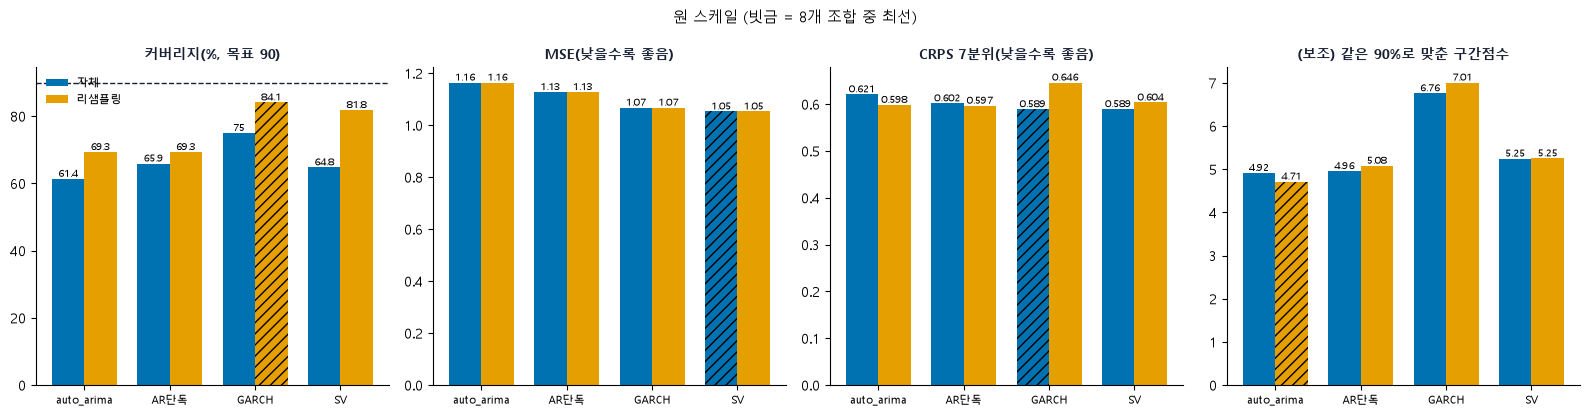

h별 CRPS(7분위):


h                    1      2      3      4
모델         방식                              
auto_arima 자체    0.314  0.560  0.727  0.883
           리샘플링  0.322  0.561  0.659  0.852
AR단독       자체    0.293  0.528  0.717  0.869
           리샘플링  0.300  0.536  0.686  0.865
GARCH      자체    0.291  0.514  0.702  0.851
           리샘플링  0.301  0.558  0.758  0.967
SV         자체    0.319  0.524  0.691  0.824
           리샘플링  0.320  0.537  0.695  0.862

origin별로 CRPS가 가장 낮은 조합 횟수(22개 origin):


,origin 수
"(SV, 자체)",9
"(SV, 리샘플링)",4
"(auto_arima, 리샘플링)",3
"(AR단독, 자체)",3
"(AR단독, 리샘플링)",2
"(auto_arima, 자체)",1


In [4]:
df_o = load("orig")
t_o = summarize(df_o, False)
show(t_o, "원 스케일 -- 22개 origin x h=1~4 평균")
plot(t_o, "원 스케일")
print("h별 CRPS(7분위):")
display(hwise(df_o).round(3))
print("origin별로 CRPS가 가장 낮은 조합 횟수(22개 origin):")
display(origin_rank(df_o))


### 3-1. 원 스케일 소결

구간 방식은 모델마다 다르게 만들었다. auto_arima·AR단독은 분산이 일정해 원 오차 리샘플링(중심화), GARCH·SV는 표준화 오차 리샘플링(중심화)이다. 두 구간 방식의 점예측은 같다.

- **모델 차이는 작다.** CRPS는 0.589(GARCH 자체, SV 자체)에서 0.646(GARCH 리샘플링)이고, 대부분은 0.589~0.621에 모여 있다. AR단독(0.597, 0.602), auto_arima(0.598, 0.621), SV 리샘플링(0.604)이 그 사이다.
- **GARCH·SV는 자체 구간이 낫다.** 표준화 오차 리샘플링은 구간이 2배 가까이 넓어서 CRPS가 더 나쁘다(GARCH 0.646 대 0.589, SV 0.604 대 0.589). auto_arima는 반대로 리샘플링이 약간 낫다(0.598 대 0.621).
- **같은 90%로 맞춘 구간점수**는 auto_arima 리샘플링 4.714, auto_arima 자체 4.915, AR단독 자체 4.957, AR단독 리샘플링 5.081, SV 자체 5.247, SV 리샘플링 5.252로 4.7~5.3에 몰려 있다. GARCH(자체 6.760, 리샘플링 7.008)만 눈에 띄게 나쁘다.
- **점예측(MSE)은 SV 1.053, GARCH 1.067, AR단독 1.127, auto_arima 1.164 순**이다.
- **h별**: h=1~2는 GARCH 자체(0.291, 0.514), h=3은 auto_arima 리샘플링(0.659), h=4는 SV 자체(0.824)가 가장 낮다. origin별로는 SV 자체가 22개 중 9개에서 가장 낮다.
- **커버리지**는 자체가 61~75%, GARCH·SV 리샘플링이 82~84%이고 AR단독·auto_arima는 61~69%다. 모두 90%에 못 미친다.


## 4. 로그 스케일 비교 (8개 조합)


로그 스케일 -- 22개 origin x h=1~4 평균 (원 스케일에서 채점)

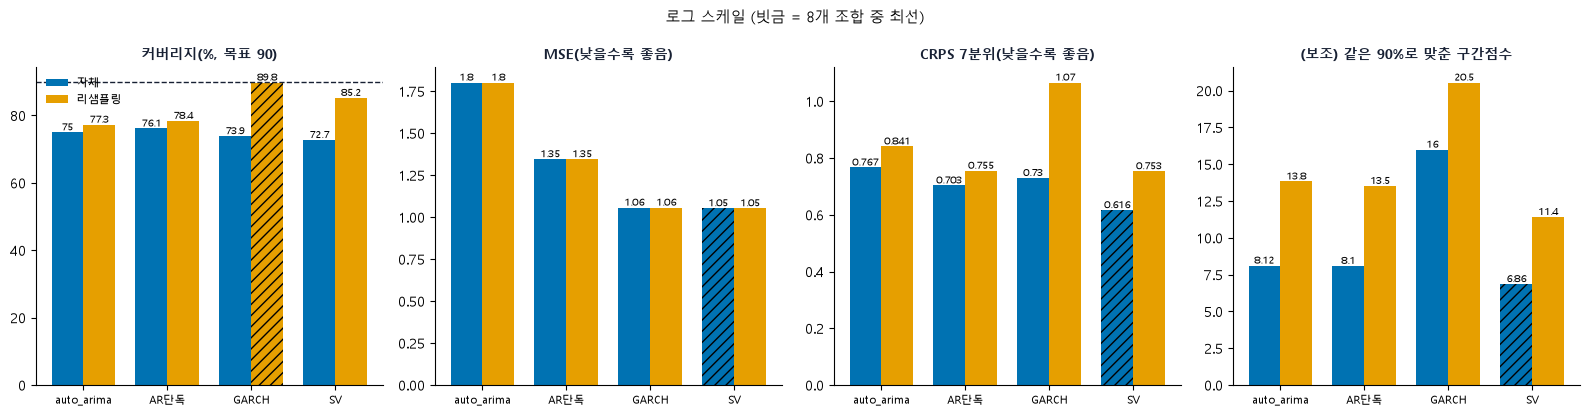

h별 CRPS(7분위):


h                    1      2      3      4
모델         방식                              
auto_arima 자체    0.336  0.613  0.929  1.188
           리샘플링  0.345  0.687  1.045  1.286
AR단독       자체    0.288  0.573  0.857  1.095
           리샘플링  0.285  0.623  0.932  1.180
GARCH      자체    0.321  0.611  0.878  1.109
           리샘플링  0.351  0.864  1.337  1.711
SV         자체    0.327  0.547  0.728  0.864
           리샘플링  0.338  0.668  0.896  1.112

origin별로 CRPS가 가장 낮은 조합 횟수(22개 origin):


,origin 수
"(SV, 자체)",12
"(AR단독, 자체)",3
"(SV, 리샘플링)",3
"(AR단독, 리샘플링)",1
"(auto_arima, 자체)",1
"(GARCH, 자체)",1
"(GARCH, 리샘플링)",1


In [5]:
df_l = load("log")
t_l = summarize(df_l, True)
show(t_l, "로그 스케일 -- 22개 origin x h=1~4 평균 (원 스케일에서 채점)")
plot(t_l, "로그 스케일")
print("h별 CRPS(7분위):")
display(hwise(df_l).round(3))
print("origin별로 CRPS가 가장 낮은 조합 횟수(22개 origin):")
display(origin_rank(df_l))


### 4-1. 로그 스케일 소결

- **로그에서는 SV 자체가 가장 낫다.** CRPS는 SV 자체 0.616, AR단독 자체 0.703, GARCH 자체 0.730, SV 리샘플링 0.753, AR단독 리샘플링 0.755, auto_arima 자체 0.767 순이다. auto_arima 리샘플링(0.841)과 GARCH 리샘플링(1.066)이 가장 나쁘다.
- **GARCH·SV는 자체 구간이 훨씬 낫다.** 표준화 오차 리샘플링은 로그에서 구간이 2.5~3배로 넓어진다(GARCH 폭 15.553, SV 7.847). 커버리지는 89.8%, 85.2%로 올라가지만 CRPS가 크게 나쁘다.
- **같은 90%로 맞춘 구간점수**도 SV 자체가 6.860으로 가장 낮고, AR단독·auto_arima 자체가 8.05~8.12, SV 리샘플링 11.4, 나머지 13.5 이상이다(GARCH 자체 15.991, GARCH 리샘플링 20.547).
- **점예측(MSE)**은 SV 1.053, GARCH 1.057로 낮은데 AR단독 1.345, auto_arima 1.802로 크게 벌어진다. 로그로 변환하면 AR단독·auto_arima의 점예측이 급등 이후 크게 빗나간다.
- **h가 길수록 차이가 커진다.** h=4 CRPS는 SV 자체 0.864, AR단독 자체 1.095, GARCH 자체 1.109, auto_arima 자체 1.188이다.
- origin별로는 SV 자체가 22개 중 12개에서 가장 낮다.


## 5. 최종 요약 -- 스케일별 최선과 원 vs 로그


In [6]:
def best_rows(t, tag):
    out = []
    for c in ["CRPS(7분위)", "90% 구간점수", "MSE"]:
        m, n = t[c].idxmin()
        out.append({"스케일": tag, "기준": c, "최선 조합": f"{m} / {n}", "값": t.loc[(m, n), c]})
    return out


best = pd.DataFrame(best_rows(t_o, "원") + best_rows(t_l, "로그"))
display(best.round(3))

w = (t_l["구간폭"] / t_o["구간폭"]).rename("로그 폭 / 원 폭")
print("같은 조합의 원 vs 로그:")
display(pd.concat([t_o[["CRPS(7분위)", "구간폭", "90% 구간점수"]].add_suffix("(원)"), t_l[["CRPS(7분위)", "구간폭", "90% 구간점수"]].add_suffix("(로그)"), w], axis=1).round(3))


,스케일,기준,최선 조합,값
0,원,CRPS(7분위),GARCH / 자체,0.589
1,원,90% 구간점수,auto_arima / 리샘플링,4.714
2,원,MSE,SV / 자체,1.053
3,로그,CRPS(7분위),SV / 자체,0.616
4,로그,90% 구간점수,SV / 자체,6.860
5,로그,MSE,SV / 자체,1.053


같은 조합의 원 vs 로그:


CRPS(7분위)(원)  구간폭(원)  90% 구간점수(원)  CRPS(7분위)(로그)  구간폭(로그)  \
모델         구간                                                                
auto_arima 자체           0.621   1.705        4.915          0.767    4.070   
           리샘플링         0.598   2.227        4.714          0.841    6.164   
AR단독       자체           0.602   1.727        4.957          0.703    4.031   
           리샘플링         0.597   2.199        5.081          0.755    5.732   
GARCH      자체           0.589   2.459        6.760          0.730    5.428   
           리샘플링         0.646   5.049        7.008          1.066   15.553   
SV         자체           0.589   1.795        5.247          0.616    3.000   
           리샘플링         0.604   3.484        5.252          0.753    7.847   

                 90% 구간점수(로그)  로그 폭 / 원 폭  
모델         구간                              
auto_arima 자체           8.117       2.387  
           리샘플링        13.827       2.768  
AR단독       자체           8.096       2.334  
           리샘플링        13.525       2.607  
GARCH      자체          15.991       2.207  
           리샘플링        20.547       3.080  
SV         자체           6.860       1.671  
           리샘플링        11.417       2.252

## 6. 기준 모델 대비 비교 -- auto_arima + 원 스케일 + 리샘플링

초반 분석(`9-3`)에서 가장 괜찮아 보였던 **auto_arima · 원 스케일 · 리샘플링 구간**을 기준(ref)으로 두고, 이후 실험의 나머지 15개 조합(모델 x 구간 방식 x 스케일)이 이보다 나은지 본다.
- 조합마다 22개 origin의 CRPS(origin별 h=1~4 평균)를 기준과 짝지어 비교: 변화율 = (조합 - 기준) / 기준, `기준보다 낮은 origin`은 22개 중 CRPS가 더 낮은 개수.
- 같은 90%로 맞춘 구간점수(90% 구간점수), MSE, 커버리지도 함께 본다(구간점수·MSE는 낮을수록 좋음).
- 22개 origin이 겹치고 유의성 검정은 하지 않는 서술 비교다.


기준: auto_arima / 원 / 리샘플링 -- CRPS 0.598, 90% 구간점수 4.71, MSE 1.164, 커버리지 69.3%


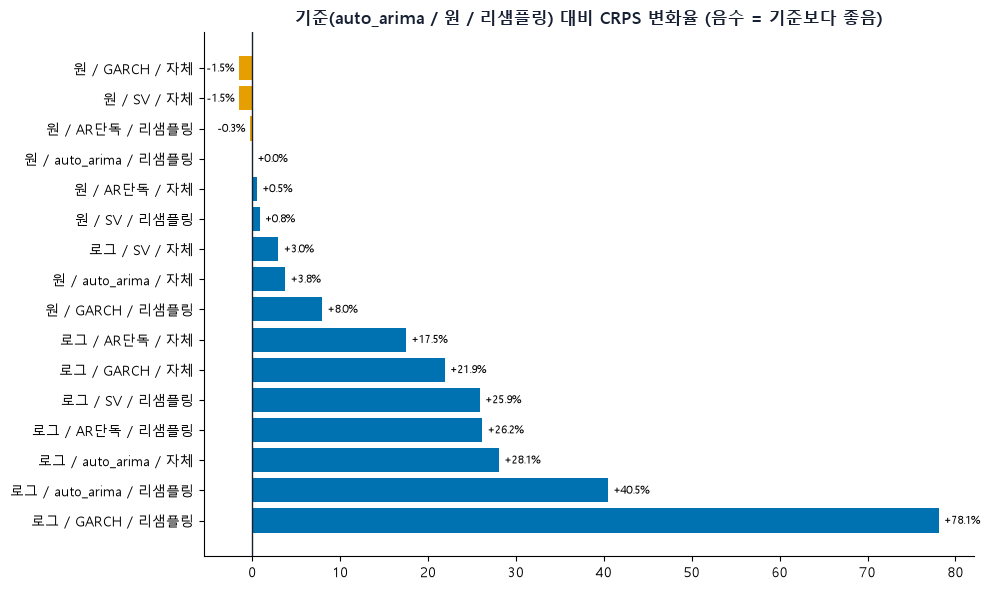

In [7]:
ref_df = df_o[(df_o["모델"] == "auto_arima") & (df_o["방식"] == "리샘플링")]
ref_c = ref_df.groupby("origin")["CRPS(7분위)"].mean()
ref_row = t_o.loc[("auto_arima", "리샘플링")]
rows = []
for scale, df, t in [("원", df_o, t_o), ("로그", df_l, t_l)]:
    for (m, n), g in df.groupby(["모델", "방식"]):
        c = g.groupby("origin")["CRPS(7분위)"].mean()
        d = c - ref_c
        r = t.loc[(m, n)]
        rows.append({"스케일": scale, "모델": m, "구간": n, "CRPS": r["CRPS(7분위)"], "CRPS 변화(%)": 100 * (r["CRPS(7분위)"] / ref_row["CRPS(7분위)"] - 1),
                     "기준보다 낮은 origin": int((d < 0).sum()), "평균 차이": d.mean(), "중앙값 차이": d.median(),
                     "90% 구간점수": r["90% 구간점수"], "MSE": r["MSE"], "커버리지(%)": r["커버리지(%)"]})
ref_tab = pd.DataFrame(rows).set_index(["스케일", "모델", "구간"]).sort_values("CRPS")
print("기준: auto_arima / 원 / 리샘플링 -- CRPS %.3f, 90%% 구간점수 %.2f, MSE %.3f, 커버리지 %.1f%%" % (ref_row["CRPS(7분위)"], ref_row["90% 구간점수"], ref_row["MSE"], ref_row["커버리지(%)"]))
display(ref_tab.round(3).style.format("{:.3f}").format({"기준보다 낮은 origin": "{:.0f}", "CRPS 변화(%)": "{:+.1f}", "커버리지(%)": "{:.1f}"})
        .highlight_between(subset=["CRPS 변화(%)"], left=-100, right=-0.001, color="#FFF1D6"))

lab = [f"{a} / {b} / {c}" for a, b, c in ref_tab.index]
fig, ax = plt.subplots(figsize=(10, 6))
vals_ = ref_tab["CRPS 변화(%)"].values
cols_ = ["#E69F00" if v < 0 else "#0072B2" for v in vals_]
bars = ax.barh(lab[::-1], vals_[::-1], color=cols_[::-1])
for b, v in zip(bars, vals_[::-1]):
    ax.text(v + (0.5 if v >= 0 else -0.5), b.get_y() + b.get_height() / 2, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="#172033", linewidth=1)
ax.set_title("기준(auto_arima / 원 / 리샘플링) 대비 CRPS 변화율 (음수 = 기준보다 좋음)", fontsize=12, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 6-1. 기준 대비 소결

**기준(auto_arima · 원 · 리샘플링)보다 뚜렷하게 나은 조합은 없다.** 기준은 CRPS 0.598, 같은 90%로 맞춘 구간점수 4.71(전체 최저), MSE 1.164, 커버리지 69.3%다.

- **CRPS가 기준보다 낮은 조합은 2개뿐이고 차이가 작다**: SV 자체(원)와 GARCH 자체(원)가 0.589로 -1.5%다. 22개 origin 중 기준보다 낮은 origin은 SV 자체 12개, GARCH 자체 7개이고, 평균 차이는 둘 다 -0.009다. AR단독 리샘플링(원)은 0.597로 사실상 같고, 나머지 원 스케일 조합은 +0.5~+8.0%다.
- **같은 90%로 맞춘 구간점수는 기준이 가장 낮다(4.71)**: SV 자체 5.25, GARCH 자체 6.76으로 구간 모양은 기준이 낫다. CRPS의 소폭 개선은 구간이 좁아서 생긴 것일 수 있다.
- **점예측(MSE)은 동시최적화가 낫다**: SV 1.053(-9.5%), GARCH 1.067(-8.3%) vs 기준 1.164. 단, SV는 AR 계수가 0 근처라 랜덤워크 점예측의 영향일 수 있다(9-5).
- **로그 스케일은 모두 기준보다 나쁘다**: 가장 좋은 SV 자체도 +3.0%이고 나머지는 +17.5%~+78.1%다.
- **커버리지를 높인 조합(GARCH·SV 리샘플링 82~90%)은 구간이 넓어 CRPS가 같거나 나쁘다**(+0.8%, +8.0%).
- 22개 origin이 겹치고 유의성 검정은 하지 않았으므로, 위 -1.5%는 기준과 구분되지 않는 수준으로 보는 것이 맞다.


### 6-2. 원 스케일에서 AR단독 리샘플링보다 CRPS가 낮은 조합

원 스케일에서 AR단독 리샘플링(CRPS 0.597)보다 CRPS가 낮은 조합은 **SV 자체**와 **GARCH 자체** 둘뿐이다. 이 3개를 커버리지, MSE, CRPS(기준 지표)로 비교한다.


,커버리지(%),MSE,CRPS(7분위),AR단독 리샘플링보다 CRPS 낮은 origin,평균 차이,중앙값 차이
조합(원 스케일),,,,,,
AR단독 / 리샘플링,69.318,1.127,0.597,0,0.000,0.000
SV / 자체,64.773,1.053,0.589,14,-0.007,-0.051
GARCH / 자체,75.000,1.067,0.589,10,-0.007,0.015


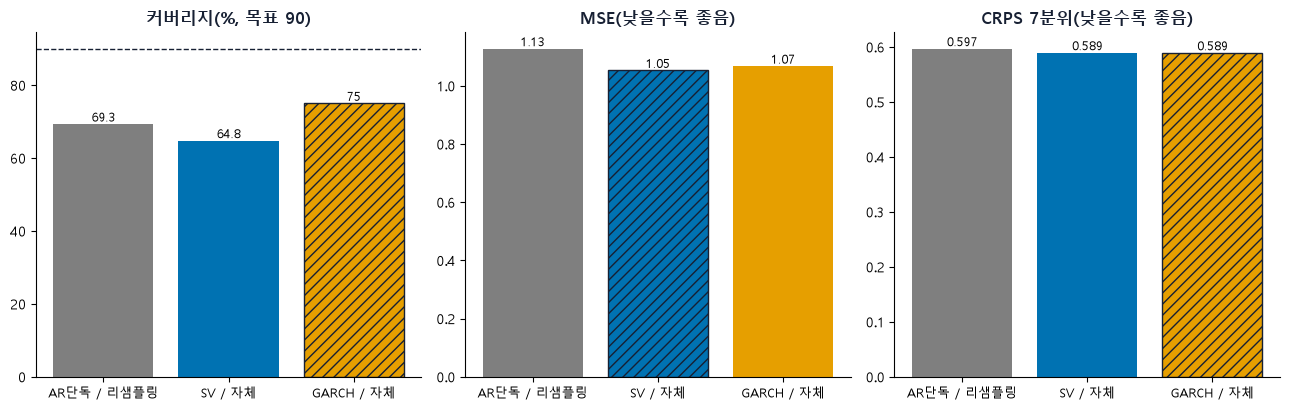

In [8]:
top3 = [("AR단독", "리샘플링"), ("SV", "자체"), ("GARCH", "자체")]
top_names = ["AR단독 / 리샘플링", "SV / 자체", "GARCH / 자체"]
ref3 = df_o[(df_o["모델"] == "AR단독") & (df_o["방식"] == "리샘플링")].groupby("origin")["CRPS(7분위)"].mean()
tabs = []
for (m, n), nm in zip(top3, top_names):
    g = df_o[(df_o["모델"] == m) & (df_o["방식"] == n)]
    c = g.groupby("origin")["CRPS(7분위)"].mean()
    d = c - ref3
    tabs.append({"조합(원 스케일)": nm, "커버리지(%)": g["적중"].mean(), "MSE": g["MSE"].mean(), "CRPS(7분위)": g["CRPS(7분위)"].mean(),
                 "AR단독 리샘플링보다 CRPS 낮은 origin": int((d < 0).sum()), "평균 차이": d.mean(), "중앙값 차이": d.median()})
top_tab = pd.DataFrame(tabs).set_index("조합(원 스케일)")
display(top_tab.round(3))

cols3 = ["#7F7F7F", "#0072B2", "#E69F00"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)")]):
    v = top_tab[c].values
    bars = ax.bar(top_names, v, color=cols3)
    score = np.abs(v - 90) if c.startswith("커버리지") else v
    for b, sc in zip(bars, score):
        if sc <= score.min() + 1e-9:
            b.set_hatch("///")
            b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c.startswith("커버리지"):
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.tick_params(axis="x", labelsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 6-2. 소결

- **CRPS**: SV 자체와 GARCH 자체가 0.589로 AR단독 리샘플링(0.597)보다 1.3% 낮다. 22개 origin 중 더 낮은 곳은 SV 자체 14개, GARCH 자체 10개이고 평균 차이는 둘 다 -0.007이다. 중앙값 차이는 SV -0.051, GARCH +0.015라서 SV 쪽이 더 일관되고 GARCH는 일부 origin이 평균을 끌어내린다.
- **MSE**: SV 1.053(-6.6%), GARCH 1.067(-5.3%)로 AR단독(1.127)보다 낮다. 동시최적화가 점예측을 바꾼 효과이며, SV는 AR 계수가 0 근처라 랜덤워크 점예측의 영향일 수 있다.
- **커버리지**: GARCH 자체 75.0%가 가장 높고(AR단독 리샘플링 69.3% 대비 +5.7%p), SV 자체는 64.8%로 오히려 낮다(-4.5%p). 셋 모두 90%에 못 미친다.
- CRPS 차이(-1.3%)는 작아 구분되지 않는 수준이고, 22개 origin이 겹쳐 유의성 검정은 하지 않았다. 개선이 뚜렷한 지표는 MSE다.


## 7. 결론

**두 스케일 모두 모델 중에서는 SV가 가장 낫고, 구간 방식은 GARCH·SV에서 자체 구간이 표준화 오차 리샘플링보다 낫다. 그리고 모든 모델에서 원 스케일이 로그 스케일보다 낫다.**

| 스케일 | CRPS 최선 | 같은 폭 구간점수 최선 | MSE 최선 |
|---|---|---|---|
| 원 | GARCH 자체·SV 자체 0.589 | auto_arima 리샘플링 4.714 | SV 1.053 |
| 로그 | SV 자체 0.616 | SV 자체 6.860 | SV 1.053 |

- **구간 방식(정석 설정)**: auto_arima·AR단독은 원 오차 리샘플링(중심화), GARCH·SV는 표준화 오차 리샘플링(중심화)을 썼다. 자체 구간과 점예측은 같아서 구간 모양만 비교된다.
- **원 스케일**: CRPS 대부분이 0.589~0.621에 모여 우열이 약하고, 같은 폭 구간점수도 4.7~5.3에 몰린다(GARCH 제외). GARCH·SV의 리샘플링은 구간이 2배 가까이 넓어져 오히려 나쁘고, auto_arima는 리샘플링이 약간 낫다.
- **로그 스케일**: SV 자체(0.616)가 가장 낫고, 점예측 MSE도 GARCH·SV(1.05)가 AR단독·auto_arima(1.35~1.80)보다 크게 좋다. h=4에서 차이가 가장 크다.
- **원 vs 로그**: 모든 모델에서 원 스케일의 CRPS가 더 낮고(예: SV 0.589 대 0.616, auto_arima 0.598 대 0.767), 로그 구간 폭은 원의 1.67~3.08배다. 로그 변환은 이 데이터에서 이득이 없다. 단, 로그에서는 동시최적화(특히 SV 자체)의 효과가 눈에 띄게 커진다.
- **커버리지**는 자체 구간이 61~76%, 리샘플링이 69~90%로 대부분 90%에 못 미친다. 표준화 오차 리샘플링이 커버리지는 높이지만 폭이 늘어난 만큼 점수에서는 이득이 없다.
- **초반 기준(auto_arima · 원 · 리샘플링) 대비**: CRPS가 더 낮은 조합은 SV 자체·GARCH 자체(원)뿐이고 차이도 -1.5%로 작다. 같은 폭 구간점수는 기준이 가장 낮고, 로그 스케일은 모두 기준보다 나쁘다. 점예측(MSE)만 동시최적화가 약 9% 낫다.
- **주의할 점**: SV의 AR 계수는 0 근처(9-5)라 점예측이 랜덤워크에 가깝다. SV의 우위는 변동성 모형화보다 랜덤워크 점예측의 영향이 클 수 있고, 이 노트북으로는 둘을 분리할 수 없다. 또 22개 origin이 겹치므로 서술 비교이고 유의성 검정은 하지 않았다.
- **의미**: 원 스케일에서는 모델을 가려 쓸 만큼의 차이가 없고, 구간 품질은 구간 방식과 폭 보정의 영향이 더 크다. 로그를 쓴다면 SV 자체 구간이 가장 낫다.
